# AIS Based Supply

## Run this example in [Colab](https://colab.research.google.com/github/SignalOceanSdk/SignalSDK/blob/master/docs/examples/jupyter/SupplyAPI/AisBasedSupply.ipynb)

Which Aframax tankers are in the US Gulf now, in ballast, and moving slowly (0 to 3 knots)?

## Setup
Install the Signal Ocean SDK:
```
pip install signal-ocean
```
You need your own API key with access to the Supply API, for the vessel classes that you query. Get your key here: https://apis.signalocean.com/profile

In [ ]:
!pip install signal-ocean

In [2]:
signal_ocean_api_key = ''  # Replace with your subscription key

In [3]:
from datetime import date

from signal_ocean import Connection
from signal_ocean.supply import (
    AisTrackingFilter,
    FromToRange,
    IncludeExcludeFilter,
    SupplyAPI,
    SupplyFilter,
    VesselClass,
    VoyageDetailsFilter,
    VoyageState,
)

connection = Connection(signal_ocean_api_key)
api = SupplyAPI(connection)

## Filters
- `ais_current_area`: the US Gulf area (id 24676). This filter takes area ids as plain numbers.
- `ais_speed`: 0 to 3 knots, so likely at berth or at anchor.
- `days_since_latest_ais`: an AIS message in the last 5 days.
- `voyage_state`: in ballast, fixed or not fixed.

In [4]:
filters = SupplyFilter(
    vessel_class=VesselClass.AFRAMAX,
    voyage_details=VoyageDetailsFilter(
        voyage_state=[VoyageState.BALLAST_FIXED, VoyageState.BALLAST_UNFIXED]
    ),
    ais_tracking=AisTrackingFilter(
        ais_current_area=IncludeExcludeFilter(values=[24676]),
        ais_speed=FromToRange(from_=0, to=3),
        days_since_latest_ais=5,
    ),
)

## Supply trend

In [5]:
trend_frame = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), filters=filters).to_data_frame()
trend_frame.tail()

,supply
date,
2026-10-27,9
2026-10-28,13
2026-10-29,15
2026-10-30,14
2026-10-31,17


<Axes: title={'center': 'Slow ballast Aframax tankers in the US Gulf'}, ylabel='Vessels'>

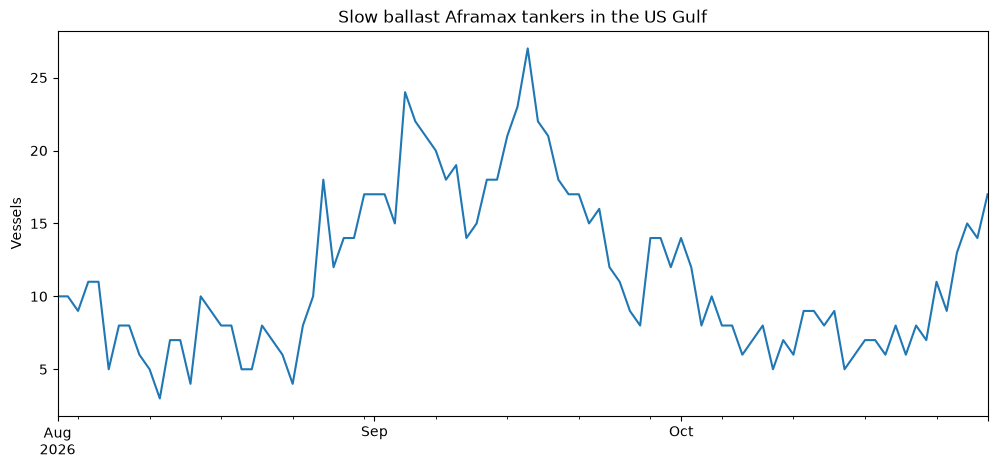

In [6]:
trend_frame.plot(y="supply", figsize=(12, 5), legend=False,
    title="Slow ballast Aframax tankers in the US Gulf", ylabel="Vessels", xlabel="")

## The vessels now

In [7]:
live_frame = api.get_live_supply(filters=filters).to_data_frame()
live_frame[
    ["imo", "voyage_state", "ais_current_area", "ais_closest_location",
     "ais_speed_average", "days_since_latest_ais", "ais_destination"]
]

,imo,voyage_state,ais_current_area,ais_closest_location,ais_speed_average,days_since_latest_ais,ais_destination
0,9528043,BallastUnfixed,US Gulf,Galveston,0.09,0.09,Galveston
1,9414034,BallastUnfixed,US Gulf,Galveston,0.03,0.09,Galveston
2,9488023,BallastUnfixed,US Gulf,Loop,0.58,0.10,New Orleans
3,9787936,BallastUnfixed,US Gulf,Galveston,0.14,0.09,Galveston
4,9683013,BallastUnfixed,US Gulf,Corpus Christi,0.04,0.09,Corpus Christi
5,9777943,BallastUnfixed,US Gulf,Galveston,0.21,0.10,Galveston
6,9518892,BallastUnfixed,US Gulf,Galveston,0.23,0.09,Galveston
7,9624067,BallastUnfixed,US Gulf,Galveston,0.61,0.10,Galveston
8,1054620,BallastUnfixed,US Gulf,Corpus Christi,0.03,0.09,Corpus Christi


In [8]:
connection.close()